In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install torch lifelines -q

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 10.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 10.0 MB/s eta 0:00:00


In [3]:
import os
import json
import ast
import copy

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader
from lifelines.utils import concordance_index

In [4]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
SELECTKBEST_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/SelectKBest/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/SelectKBest/"

os.makedirs(SELECTKBEST_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = SELECTKBEST_OUTPUT_DIR + "hcc_selectkbest_train_selected.csv"

BEST_PARAMS_JSON_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_best_hyperparameters.json"
BEST_PARAMS_CSV_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_best_hyperparameters.csv"

MODEL_PATH = MODEL_DIR + "hcc_selectkbest_deepsurv_model.pth"
TRAINING_SUMMARY_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_final_training_summary.csv"
LOSS_HISTORY_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_loss_history.csv"
LOSS_PLOT_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_training_loss.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"

In [5]:
train_data = pd.read_csv(TRAIN_PATH)

print("Train data shape:", train_data.shape)
train_data.head()

Train data shape: (1085, 52)


,SAMPLE_COVERAGE,TUMOR_SIZE,MUT_ALB,MUT_ARID1A,MUT_ARID1B,MUT_UPF1,MUT_WHSC1,MUT_ZFHX3,CNA_CDKN2A,CNA_KMT2B,...,RESECTION_MARGIN_R0,NEOADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_No,ADJUVANT_SYSTEMIC_THERAPY_Yes,PALLIATIVE_SYSTEMIC_THERPAY_,PALLIATIVE_SYSTEMIC_THERPAY_No,PALLIATIVE_SYSTEMIC_THERPAY_Yes,OS_MONTHS,OS_EVENT
0,886.0,6.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,82.296,0
1,755.0,6.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,51.324,1
2,635.0,5.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,6.600,1
3,537.0,6.4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,24.480,0
4,1056.0,3.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,14.592,1


In [6]:
print("Train missing values:", int(train_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

Train missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64


In [7]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [8]:
COLS_TO_DROP = []

if COLS_TO_DROP:
    train_data = train_data.drop(columns=COLS_TO_DROP)

train_data.shape

(1085, 52)

In [9]:
DEPENDENT_COLUMNS = ["OS_MONTHS", "OS_EVENT"]
ID_COLUMNS = ["PATIENT_ID", "SAMPLE_ID"]

GENES = [
    col for col in train_data.columns
    if col not in DEPENDENT_COLUMNS + ID_COLUMNS
]

print("Feature count:", len(GENES))
GENES[:10]

Feature count: 50


['SAMPLE_COVERAGE',
 'TUMOR_SIZE',
 'MUT_ALB',
 'MUT_ARID1A',
 'MUT_ARID1B',
 'MUT_UPF1',
 'MUT_WHSC1',
 'MUT_ZFHX3',
 'CNA_CDKN2A',
 'CNA_KMT2B']

In [10]:
X = train_data[GENES].copy()
y = train_data[DEPENDENT_COLUMNS].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1085, 50)
y shape: (1085, 2)


In [11]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RANDOM_STATE = 42

print("Device:", DEVICE)

Device: cpu


In [12]:
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_STATE)

In [13]:
best_params_df = pd.read_csv(BEST_PARAMS_CSV_PATH)
best_params_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_c_index
0,"[128, 64]",0.0,128,LeakyReLU,AdamW,0.0001,0.005,20,100,44.0,0.729448


In [14]:
best_row = best_params_df.iloc[0].copy()

BEST_HIDDEN_LAYERS = ast.literal_eval(best_row["hidden_layers"])
BEST_DROPOUT_RATE = float(best_row["dropout_rate"])
BEST_BATCH_SIZE = int(best_row["batch_size"])
BEST_ACTIVATION = str(best_row["activation"])
BEST_OPTIMIZER = str(best_row["optimizer"])
BEST_WEIGHT_DECAY = float(best_row["weight_decay"])
BEST_LEARNING_RATE = float(best_row["learning_rate"])
BEST_PATIENCE = int(best_row["patience"])
BEST_EPOCHS = int(best_row["epochs"])
BEST_MEAN_BEST_EPOCH = float(best_row["mean_best_epoch"])
BEST_MEAN_C_INDEX = float(best_row["mean_c_index"])

print("Best hidden layers:", BEST_HIDDEN_LAYERS)
print("Best dropout rate:", BEST_DROPOUT_RATE)
print("Best batch size:", BEST_BATCH_SIZE)
print("Best activation:", BEST_ACTIVATION)
print("Best optimizer:", BEST_OPTIMIZER)
print("Best weight decay:", BEST_WEIGHT_DECAY)
print("Best learning rate:", BEST_LEARNING_RATE)
print("Best patience:", BEST_PATIENCE)
print("Best epochs:", BEST_EPOCHS)
print("Best mean validation C-index:", round(BEST_MEAN_C_INDEX, 4))

Best hidden layers: [128, 64]
Best dropout rate: 0.0
Best batch size: 128
Best activation: LeakyReLU
Best optimizer: AdamW
Best weight decay: 0.0001
Best learning rate: 0.005
Best patience: 20
Best epochs: 100
Best mean validation C-index: 0.7294


In [15]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [16]:
def nll_loss(preds, durations, events):
    order = torch.argsort(durations, descending=True)

    hazards = preds[order].reshape(-1)
    events = events[order].reshape(-1)

    log_risk = torch.logcumsumexp(hazards, dim=0)
    uncensored_loss = hazards - log_risk
    censored_loss = uncensored_loss * events

    return -torch.sum(censored_loss) / torch.sum(events)

In [17]:
def build_optimizer(model, optimizer_name, learning_rate, weight_decay):
    if optimizer_name == "Adam":
        return optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "AdamW":
        return optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    elif optimizer_name == "RMSprop":
        return optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    else:
        raise ValueError(f"Unsupported optimizer: {optimizer_name}")

In [18]:
X_train_tensor = torch.tensor(X.values, dtype=torch.float32)
y_train_duration = torch.tensor(y[DURATION_COL].values, dtype=torch.float32)
y_train_event = torch.tensor(y[EVENT_COL].values, dtype=torch.float32)

train_dataset = TensorDataset(X_train_tensor, y_train_duration, y_train_event)
train_loader = DataLoader(
    train_dataset,
    batch_size=BEST_BATCH_SIZE,
    shuffle=True
)

print("Training tensor shape:", X_train_tensor.shape)
print("Batch size:", BEST_BATCH_SIZE)

Training tensor shape: torch.Size([1085, 50])
Batch size: 128


In [19]:
input_dim = X.shape[1]

model = DeepSurv(
    input_dim=input_dim,
    hidden_layers=BEST_HIDDEN_LAYERS,
    dropout_rate=BEST_DROPOUT_RATE,
    activation_name=BEST_ACTIVATION
).to(DEVICE)

optimizer = build_optimizer(
    model=model,
    optimizer_name=BEST_OPTIMIZER,
    learning_rate=BEST_LEARNING_RATE,
    weight_decay=BEST_WEIGHT_DECAY
)

In [20]:
loss_history = []

for epoch in range(BEST_EPOCHS):
    model.train()
    epoch_losses = []

    for batch_X, batch_duration, batch_event in train_loader:
        batch_X = batch_X.to(DEVICE)
        batch_duration = batch_duration.to(DEVICE)
        batch_event = batch_event.to(DEVICE)

        optimizer.zero_grad()
        preds = model(batch_X)
        loss = nll_loss(preds, batch_duration, batch_event)
        loss.backward()
        optimizer.step()

        epoch_losses.append(loss.item())

    mean_epoch_loss = np.mean(epoch_losses)
    loss_history.append(mean_epoch_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1}/{BEST_EPOCHS} - Loss: {mean_epoch_loss:.4f}")

Epoch 1/100 - Loss: 9.7927
Epoch 10/100 - Loss: 3.6591
Epoch 20/100 - Loss: 3.6287
Epoch 30/100 - Loss: 3.6115
Epoch 40/100 - Loss: 3.6100
Epoch 50/100 - Loss: 3.5917
Epoch 60/100 - Loss: 3.6269
Epoch 70/100 - Loss: 3.6391
Epoch 80/100 - Loss: 3.6257
Epoch 90/100 - Loss: 3.5793
Epoch 100/100 - Loss: 3.6128


In [21]:
model.eval()

X_all_tensor = torch.tensor(X.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    train_preds = model(X_all_tensor).cpu().numpy().reshape(-1)

train_c_index = concordance_index(
    y[DURATION_COL].values,
    -train_preds,
    y[EVENT_COL].values
)

print(f"Training Concordance Index: {train_c_index:.4f}")

Training Concordance Index: 0.7335


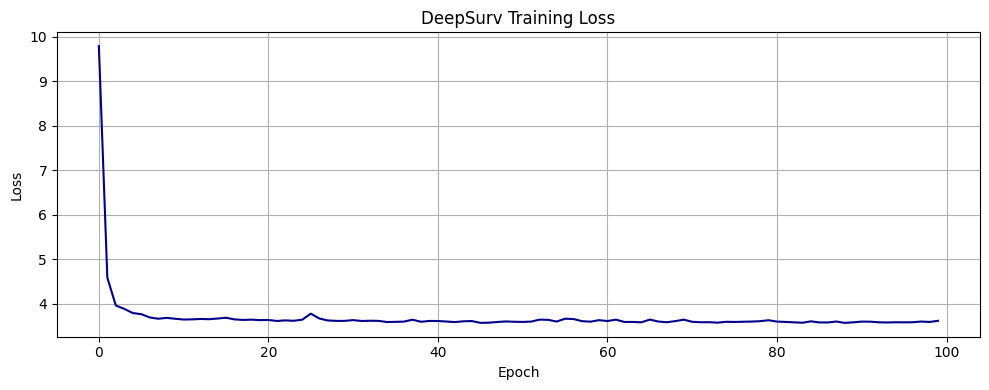

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_training_loss.png'

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(loss_history, color="darkblue")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DeepSurv Training Loss")
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

LOSS_PLOT_PATH

In [23]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "input_dim": input_dim,
    "hidden_layers": BEST_HIDDEN_LAYERS,
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_c_index": BEST_MEAN_C_INDEX,
    "feature_columns": GENES,
    "duration_col": DURATION_COL,
    "event_col": EVENT_COL
}

torch.save(checkpoint, MODEL_PATH)

print("Model saved to:", MODEL_PATH)

Model saved to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/SelectKBest/hcc_selectkbest_deepsurv_model.pth


In [24]:
loss_history_df = pd.DataFrame({
    "epoch": np.arange(1, len(loss_history) + 1),
    "loss": loss_history
})

loss_history_df.to_csv(LOSS_HISTORY_PATH, index=False)

LOSS_HISTORY_PATH

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_loss_history.csv'

In [25]:
training_summary_df = pd.DataFrame([{
    "hidden_layers": json.dumps(BEST_HIDDEN_LAYERS),
    "dropout_rate": BEST_DROPOUT_RATE,
    "batch_size": BEST_BATCH_SIZE,
    "activation": BEST_ACTIVATION,
    "optimizer": BEST_OPTIMIZER,
    "weight_decay": BEST_WEIGHT_DECAY,
    "learning_rate": BEST_LEARNING_RATE,
    "patience": BEST_PATIENCE,
    "epochs": BEST_EPOCHS,
    "mean_best_epoch": BEST_MEAN_BEST_EPOCH,
    "mean_validation_c_index": BEST_MEAN_C_INDEX,
    "training_c_index": train_c_index,
    "model_path": MODEL_PATH
}])

training_summary_df.to_csv(TRAINING_SUMMARY_PATH, index=False)

training_summary_df

,hidden_layers,dropout_rate,batch_size,activation,optimizer,weight_decay,learning_rate,patience,epochs,mean_best_epoch,mean_validation_c_index,training_c_index,model_path
0,"[128, 64]",0.0,128,LeakyReLU,AdamW,0.0001,0.005,20,100,44.0,0.729448,0.733468,/content/drive/MyDrive/IEEE Project/Hepatocell...


In [26]:
MODEL_PATH, TRAINING_SUMMARY_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/SelectKBest/hcc_selectkbest_deepsurv_model.pth',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_final_training_summary.csv')

The `SelectKBest` DeepSurv best-model notebook successfully took the winning hyperparameter configuration from the tuning stage and retrained that exact model on the full `SelectKBest` training dataset. This notebook was the transition point from cross-validation-based model selection to the final reproducible trained neural survival model.

The selected configuration carried forward exactly from the tuning notebook:
- Hidden layers: `[128, 64]`
- Dropout rate: `0.0`
- Batch size: `128`
- Activation: `LeakyReLU`
- Optimizer: `AdamW`
- Weight decay: `0.0001`
- Learning rate: `0.005`
- Patience: `20`
- Epochs: `100`
- Best mean validation C-index from tuning: `0.7298`

The final retraining used the full training tensor of shape `torch.Size([1085, 50])`, which confirms the model was trained on all 1085 patients and 50 selected features. This is exactly what we want at this stage: once tuning is complete, the final model should absorb all available training information before test evaluation.

The loss trajectory shows that optimization behaved sensibly. Training loss dropped sharply from `9.7927` at epoch 1 to the mid-`3.6` range by epoch 10, then gradually stabilized with smaller fluctuations through the rest of training. That pattern is healthy for DeepSurv: it suggests the network learned the main structure quickly and then spent the remaining epochs refining the ranking objective rather than diverging or collapsing.

The final training Concordance Index was `0.7335`. This is a strong result and, importantly, it is close to the cross-validated mean validation C-index of `0.7298`. That closeness is reassuring because it suggests the final retrained model is consistent with what was observed during tuning, rather than suddenly inflating on the full training set. In other words, the selected architecture appears stable.

A few observations stand out from this notebook:
- The best architecture again remained the two-layer `128 -> 64` network, reinforcing that this is the most reliable DeepSurv structure across these experiments.
- `LeakyReLU` continued to be the preferred activation, which is now a repeated pattern rather than an isolated result.
- Unlike `Exp_1`, the `SelectKBest` branch benefited from mild L2 regularization through `AdamW` with `weight_decay = 0.0001`.
- The final training C-index staying close to the tuning C-index suggests the model is neither undertrained nor showing obvious instability.

Overall, the outcome of this notebook is a finalized and reproducible `SelectKBest` DeepSurv model, trained on the full training cohort with the best verified hyperparameters. The model is now ready for final held-out evaluation on the untouched test set.